## BEST MODEL PREDICTIONS COMPUTATION

In the other file models.ipynb we have build the best model by implementing a grid search through the hyperparameters and then comparing the best model using undersample method and the best model using the weighted method. This document is only used to prepare the predictions in a more clean way to send to make the final submision.


In [12]:
%reload_ext autoreload
%autoreload 2
import numpy as np
from implementations import *
from helpers import *
from aux_exploratory_data_analysis import *
from aux_cleaning_functions import *
from aux_preprocessing import *
from aux_grid_search import *
import csv

In [19]:
x_train1, x_test, y_train, train_ids, test_ids = load_csv_data("data")
# We transform the data form (-1,1) to (0,1) 
Y_tr = (y_train + 1) / 2

In [22]:
x_train, x_validation, x_te, y_train, y_validation, y_te = split_data(x_train1, Y_tr, ratiotrain= 0.7, ratiovalidation = 0.15, seed=None)

x_te = np.concatenate((x_validation, x_te), axis = 0)
y_te = np.concatenate((y_validation, y_te), axis = 0)

print (x_train.shape, y_train.shape)
print (x_validation.shape, y_validation.shape)
print (x_te.shape, y_te.shape)

(229694, 321) (229694,)
(49220, 321) (49220,)
(98441, 321) (98441,)


We look at the best combination of hyperparameters found on the models file and import it.

Iter     0 | Loss = 0.675733 | Grad = 0.4245
Iter   100 | Loss = 0.489883 | Grad = 0.0438
Iter   200 | Loss = 0.479198 | Grad = 0.0251
Iter   300 | Loss = 0.474672 | Grad = 0.0182
Iter   400 | Loss = 0.472049 | Grad = 0.0145
Iter   500 | Loss = 0.470293 | Grad = 0.0122
Iter   600 | Loss = 0.469012 | Grad = 0.0106
Iter   700 | Loss = 0.468025 | Grad = 0.0094
Iter   800 | Loss = 0.467238 | Grad = 0.0084
Iter   900 | Loss = 0.466594 | Grad = 0.0077
Iter  1000 | Loss = 0.466057 | Grad = 0.0070
Iter  1100 | Loss = 0.465602 | Grad = 0.0065
Iter  1200 | Loss = 0.465212 | Grad = 0.0060
Iter  1300 | Loss = 0.464873 | Grad = 0.0056
Iter  1400 | Loss = 0.464576 | Grad = 0.0053
Iter  1500 | Loss = 0.464313 | Grad = 0.0050
Iter  1600 | Loss = 0.464078 | Grad = 0.0047
Iter  1700 | Loss = 0.463867 | Grad = 0.0045
Iter  1800 | Loss = 0.463677 | Grad = 0.0043
Iter  1900 | Loss = 0.463503 | Grad = 0.0041
Iter  2000 | Loss = 0.463345 | Grad = 0.0039
Iter  2100 | Loss = 0.463199 | Grad = 0.0037
Iter  2200

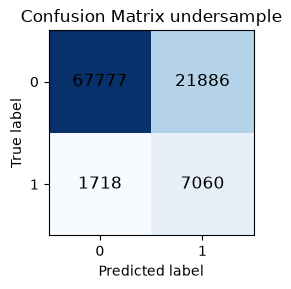

We have obtained a model using undersample with an accuracy of accuracy = 0.7602218587783546, a recall of recall = 0.8042834358623833 and a fbeta score of F_beta = 0.551063099066471


In [25]:
thr_nans = 0.3
method = "undersample"
gamma = 0.1
threshold = 0.5

X_tr_base = x_train.copy()
y_tr_base = y_train.copy()
X_te_base = x_te.copy()
y_te_base = y_te.copy()
keep_mask = remove_nan_feat(X_tr_base, threshold= thr_nans)

X_clean_nan_tr = X_tr_base[:,keep_mask]
X_clean_nan_te = X_te_base[:,keep_mask]
X_clean_nan_test = x_test[:,keep_mask]
cat_mask, num_mask = detect_categorical_features(X_clean_nan_tr, max_unique=30)

X_imp_tr,medians_tr = impute_numerical(X_clean_nan_tr, num_mask, medians=None, means=None, strategy='medians')
X_imp_tr,modes_tr = impute_categorical(X_imp_tr, cat_mask, modes=None)
X_imp_te, _ = impute_numerical(X_clean_nan_te, num_mask, medians=medians_tr, strategy='medians')
X_imp_te, _ = impute_categorical(X_imp_te, cat_mask, modes=modes_tr)
X_imp_test, _ = impute_numerical(X_clean_nan_test, num_mask, medians=medians_tr, strategy='medians')
X_imp_test, _ = impute_categorical(X_imp_test, cat_mask, modes=modes_tr)

X_std_tr, means_tr, stds_tr= standardize_features(X_imp_tr, num_mask, means=None, stds=None)
X_std_te, _, _ = standardize_features(X_imp_te, num_mask, means=means_tr, stds=stds_tr)
X_std_test, _, _ = standardize_features(X_imp_test, num_mask, means=means_tr, stds=stds_tr)


X_ohe_tr, categories = one_hot_encode(X_std_tr, cat_mask)   
X_ohe_te, _ = one_hot_encode(X_std_te, cat_mask,categories = categories)
X_ohe_test, _ = one_hot_encode(X_std_test, cat_mask,categories = categories)


mask = feature_target_correlation(X_ohe_tr, y_tr_base, threshold_elimination=0.01)
X_cleaned_tr = X_ohe_tr[:, mask]
mask_correlated_variables = filter_colinear_features (X_cleaned_tr, y_tr_base, 0.9)
X_thr_train = X_cleaned_tr[:, mask_correlated_variables]
X_thr_te = X_ohe_te[:, mask][:, mask_correlated_variables]
X_thr_test = X_ohe_test[:, mask][:, mask_correlated_variables]

X_bal, Y_bal = balance_data (X_thr_train, y_tr_base,method = method, random_state=None)
w,loss = logistic_regression(Y_bal, X_bal, np.zeros(X_bal.shape[1] + 1), 10000 ,gamma,1e-6)

preds, _ = predict_with_threshold(X_thr_te, w, threshold = threshold)
fbeta = f_beta_score(y_te_base, preds)
acc = accuracy_numpy(y_te_base, preds)
recall = recall_numpy(y_te_base, preds)
cm = confusion_matrix_numpy(y_te_base, preds, method = method)
print (f"We have obtained a model using {method} with an accuracy of accuracy = {acc}, a recall of recall = {recall} and a fbeta score of F_beta = {fbeta}")


In [26]:
y_pred, _ =  predict_with_threshold(X_thr_test, w, threshold = threshold)
y_final_preds = 2*y_pred - 1
create_csv_submission(test_ids, y_final_preds, "final_preds.csv")